<a href="https://colab.research.google.com/github/byAnree/AF3_IAM/blob/main/AF3_IAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AF 3: Aplicacion de Clustering
2077734 - Renato López Trujillo

2121978 - Edgar Andree Noyola Rangel

2226630 - Arely Carrillo Sustaita

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from google.colab import files

# Usamos la ruta completa del archivo .csv
df = pd.read_csv("stroke_limpio.csv")
print(df.shape)

(5110, 20)


In [8]:
y_stroke = df["stroke"].copy()                       # se guarda para la Sección 4
X = df.drop(columns=["stroke", "id"], errors="ignore")

cols_continuas = ["age", "avg_glucose_level", "bmi"]
X_num = X[cols_continuas]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

print(pd.DataFrame(X_scaled, columns=cols_continuas).describe().round(3))

            age  avg_glucose_level       bmi
count  5110.000           5110.000  5110.000
mean      0.000              0.000    -0.000
std       1.000              1.000     1.000
min      -1.908             -1.127    -2.411
25%      -0.806             -0.638    -0.658
50%       0.078             -0.315    -0.099
75%       0.786              0.175     0.512
max       1.715              3.657     8.928


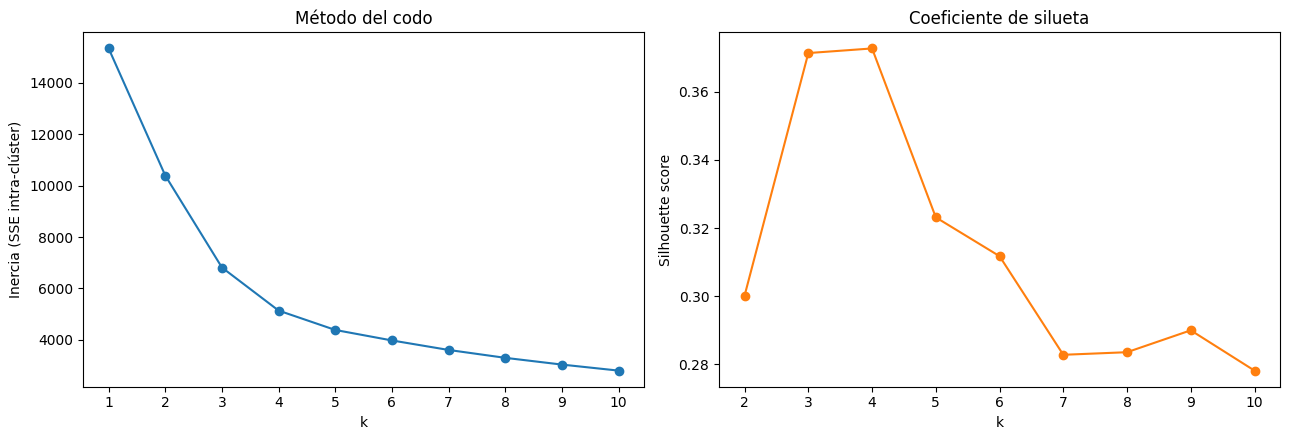

k=2: silueta=0.3002
k=3: silueta=0.3714
k=4: silueta=0.3727
k=5: silueta=0.3231
k=6: silueta=0.3117
k=7: silueta=0.2828
k=8: silueta=0.2835
k=9: silueta=0.2899
k=10: silueta=0.2781


In [9]:
rango_k = range(1, 11)
inercias = []
siluetas = {}

for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inercias.append(km.inertia_)
    if k > 1:                                  # la silueta no existe para k=1
        siluetas[k] = silhouette_score(X_scaled, km.labels_)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(list(rango_k), inercias, marker="o")
ax[0].set_title("Método del codo")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inercia (SSE intra-clúster)")
ax[0].set_xticks(list(rango_k))

ax[1].plot(list(siluetas.keys()), list(siluetas.values()), marker="o", color="tab:orange")
ax[1].set_title("Coeficiente de silueta")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silhouette score")
ax[1].set_xticks(list(siluetas.keys()))

plt.tight_layout()
plt.show()

for k, s in siluetas.items():
    print(f"k={k}: silueta={s:.4f}")

           age  avg_glucose_level    bmi
cluster                                 
0        60.03              89.54  27.74
1        41.52              90.32  39.03
2        17.89              92.67  22.81
3        60.54             207.30  32.75


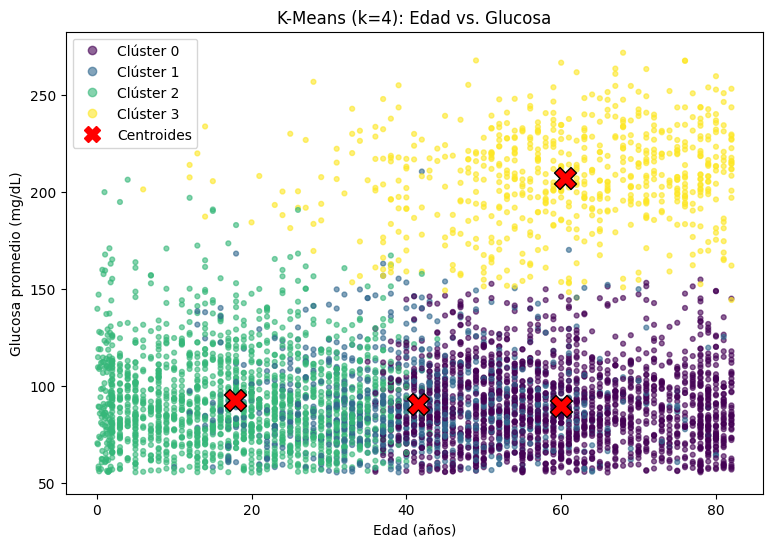

In [10]:
K_OPT = 4

kmeans = KMeans(n_clusters=K_OPT, n_init=10, random_state=42)
etiquetas = kmeans.fit_predict(X_scaled)

# Centroides en escala original (más interpretables)
centroides_orig = scaler.inverse_transform(kmeans.cluster_centers_)
centroides_df = pd.DataFrame(centroides_orig, columns=cols_continuas).round(2)
centroides_df.index.name = "cluster"
print(centroides_df)

# Datos originales con su clúster
df_plot = X_num.copy()
df_plot["cluster"] = etiquetas

plt.figure(figsize=(9, 6))
scatter = plt.scatter(df_plot["age"], df_plot["avg_glucose_level"],
                      c=df_plot["cluster"], cmap="viridis", s=12, alpha=0.6)
plt.scatter(centroides_df["age"], centroides_df["avg_glucose_level"],
            c="red", marker="X", s=250, edgecolor="black", label="Centroides")
plt.xlabel("Edad (años)")
plt.ylabel("Glucosa promedio (mg/dL)")
plt.title(f"K-Means (k={K_OPT}): Edad vs. Glucosa")
plt.legend(*scatter.legend_elements(), title="Clúster", loc="upper left")
plt.legend(handles=scatter.legend_elements()[0] + [plt.Line2D([], [], marker="X", color="red", linestyle="", markersize=12)],
           labels=[f"Clúster {i}" for i in range(K_OPT)] + ["Centroides"], loc="upper left")
plt.show()

stroke      0    1
cluster           
0        1736  141
1         907   15
2        1635    4
3         583   89
stroke       0      1
cluster              
0        92.49   7.51
1        98.37   1.63
2        99.76   0.24
3        86.76  13.24


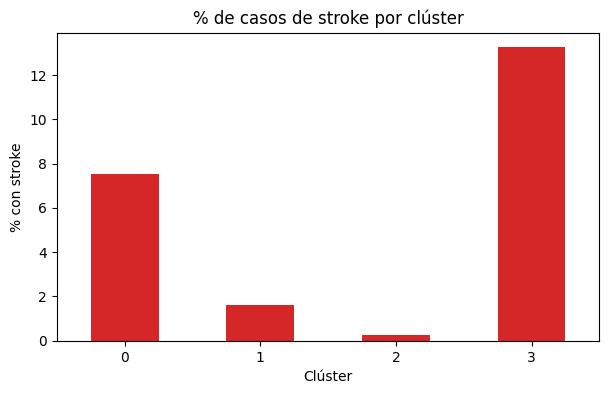


Clúster con mayor % de stroke: 3 (13.24%)
Tasa global de stroke: 4.87%

Perfil promedio por clúster:
          age  avg_glucose_level   bmi
cluster                               
0        60.0               89.5  27.7
1        41.5               90.2  39.1
2        17.9               92.7  22.8
3        60.5              207.2  32.8


In [11]:
df_val = X_num.copy()
df_val["cluster"] = etiquetas
df_val["stroke"] = y_stroke.values

# Conteos y porcentaje por fila (dentro de cada clúster)
print(pd.crosstab(df_val["cluster"], df_val["stroke"]))
tabla_pct = pd.crosstab(df_val["cluster"], df_val["stroke"], normalize="index") * 100
print(tabla_pct.round(2))

tabla_pct[1].plot(kind="bar", color="tab:red", figsize=(7, 4))
plt.title("% de casos de stroke por clúster")
plt.xlabel("Clúster")
plt.ylabel("% con stroke")
plt.xticks(rotation=0)
plt.show()

mayor = tabla_pct[1].idxmax()
print(f"\nClúster con mayor % de stroke: {mayor} ({tabla_pct.loc[mayor, 1]:.2f}%)")
print(f"Tasa global de stroke: {y_stroke.mean()*100:.2f}%")
print("\nPerfil promedio por clúster:")
print(df_val.groupby("cluster")[cols_continuas].mean().round(1))